<a href="https://colab.research.google.com/github/Welshell/recommender-systems/blob/main/recommender_system.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity #use to define difference between 2 vectors... like euclidian distance
# import warnings

# # Ignore all warnings
# warnings.filterwarnings('ignore')

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving books.csv to books.csv
Saving ratings.csv to ratings.csv
Saving users.csv to users.csv


In [ ]:
books = pd.read_csv('books.csv', sep=';', encoding='latin-1', on_bad_lines='skip')
users = pd.read_csv('users.csv', sep=';', encoding='latin-1', on_bad_lines='skip')
ratings = pd.read_csv('ratings.csv', sep=';', encoding='latin-1', on_bad_lines='skip')

/tmp/ipykernel_3800/1797699358.py:1: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  books = pd.read_csv('books.csv', sep=';', encoding='latin-1', on_bad_lines='skip')


In [ ]:
books.head(2)

,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...


In [ ]:
users.head(2)

,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0


In [ ]:
ratings.head(2)

,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5


In [ ]:
# to check missing values and other stuffs
print(books.shape)
print(users.shape)
print(ratings.shape)

(271360, 8)
(278858, 3)
(1149780, 3)


In [ ]:
# Check for missing values in each dataset
print("Missing values in Books Dataset:")
print(books.isnull().sum(), "\n")

print("Missing values in Users Dataset:")
print(users.isnull().sum(), "\n")

print("Missing values in Ratings Dataset:")
print(ratings.isnull().sum())

Missing values in Books Dataset:
ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            0
Image-URL-M            0
Image-URL-L            3
dtype: int64 

Missing values in Users Dataset:
User-ID          0
Location         0
Age         110762
dtype: int64 

Missing values in Ratings Dataset:
User-ID        0
ISBN           0
Book-Rating    0
dtype: int64


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
sns.set_theme(style="whitegrid")

/tmp/ipykernel_3800/81767277.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


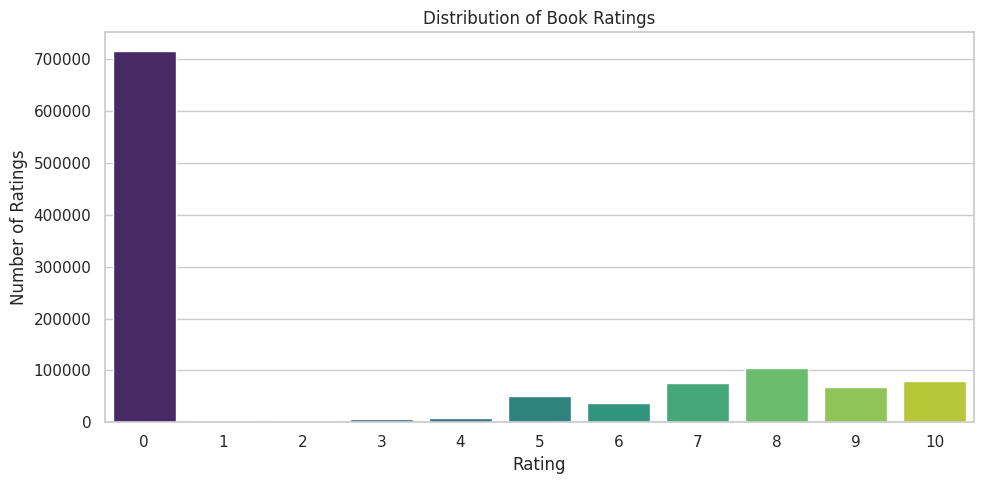

In [ ]:
# 1. Rating distribution
rating_counts = ratings['Book-Rating'].value_counts().sort_index()

plt.figure(figsize=(10, 5))
sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values,
    palette='viridis'
)
plt.title("Distribution of Book Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.tight_layout()
plt.show()


In [ ]:
# Merge the ratings dataset with the books dataset using 'ISBN' as the key
ratings_with_name = ratings.merge(books,on='ISBN')
ratings_with_name.head(2)

,User-ID,ISBN,Book-Rating,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,276725,034545104X,0,Flesh Tones: A Novel,M. J. Rose,2002,Ballantine Books,http://images.amazon.com/images/P/034545104X.0...,http://images.amazon.com/images/P/034545104X.0...,http://images.amazon.com/images/P/034545104X.0...
1,276726,0155061224,5,Rites of Passage,Judith Rae,2001,Heinle,http://images.amazon.com/images/P/0155061224.0...,http://images.amazon.com/images/P/0155061224.0...,http://images.amazon.com/images/P/0155061224.0...
2,276727,0446520802,0,The Notebook,Nicholas Sparks,1996,Warner Books,http://images.amazon.com/images/P/0446520802.0...,http://images.amazon.com/images/P/0446520802.0...,http://images.amazon.com/images/P/0446520802.0...
3,276729,052165615X,3,Help!: Level 1,Philip Prowse,1999,Cambridge University Press,http://images.amazon.com/images/P/052165615X.0...,http://images.amazon.com/images/P/052165615X.0...,http://images.amazon.com/images/P/052165615X.0...
4,276729,0521795028,6,The Amsterdam Connection : Level 4 (Cambridge ...,Sue Leather,2001,Cambridge University Press,http://images.amazon.com/images/P/0521795028.0...,http://images.amazon.com/images/P/0521795028.0...,http://images.amazon.com/images/P/0521795028.0...
5,276733,2080674722,0,Les Particules Elementaires,Michel Houellebecq,1998,Flammarion,http://images.amazon.com/images/P/2080674722.0...,http://images.amazon.com/images/P/2080674722.0...,http://images.amazon.com/images/P/2080674722.0...
6,276744,038550120X,7,A Painted House,JOHN GRISHAM,2001,Doubleday,http://images.amazon.com/images/P/038550120X.0...,http://images.amazon.com/images/P/038550120X.0...,http://images.amazon.com/images/P/038550120X.0...
7,276746,0425115801,0,Lightning,Dean R. Koontz,1996,Berkley Publishing Group,http://images.amazon.com/images/P/0425115801.0...,http://images.amazon.com/images/P/0425115801.0...,http://images.amazon.com/images/P/0425115801.0...
8,276746,0449006522,0,Manhattan Hunt Club,JOHN SAUL,2002,Ballantine Books,http://images.amazon.com/images/P/0449006522.0...,http://images.amazon.com/images/P/0449006522.0...,http://images.amazon.com/images/P/0449006522.0...
9,276746,0553561618,0,Dark Paradise,TAMI HOAG,1994,Bantam,http://images.amazon.com/images/P/0553561618.0...,http://images.amazon.com/images/P/0553561618.0...,http://images.amazon.com/images/P/0553561618.0...


In [ ]:
num_rating_df = ratings_with_name.groupby('Book-Title').count()['Book-Rating'].reset_index()
num_rating_df.rename(columns={'Book-Rating':'num_ratings'},inplace=True)
num_rating_df.head(2)

,Book-Title,num_ratings
0,A Light in the Storm: The Civil War Diary of ...,4
1,Always Have Popsicles,1


In [ ]:
# Calculate the average rating for each book
avg_rating_df = ratings_with_name.groupby('Book-Title')['Book-Rating'].mean().reset_index()

# Rename the column for better understanding
avg_rating_df.rename(columns={'Book-Rating': 'avg_rating'}, inplace=True)

avg_rating_df.head(2)

,Book-Title,avg_rating
0,A Light in the Storm: The Civil War Diary of ...,2.25
1,Always Have Popsicles,0.00


In [ ]:
# Merge the number of ratings and average ratings DataFrames on 'Book-Title'
popular_df = num_rating_df.merge(avg_rating_df, on='Book-Title')

popular_df.head(2)

,Book-Title,num_ratings,avg_rating
0,A Light in the Storm: The Civil War Diary of ...,4,2.25
1,Always Have Popsicles,1,0.00


In [ ]:
# Apply a filter to include only books with at least 300 ratings
popular_df = popular_df[popular_df['num_ratings'] >= 300]

# Sort by highest average rating in descending order and take the top 50 books
popular_df = popular_df.sort_values('avg_rating', ascending=False).head(50)

In [ ]:
# Ensure we only perform the merge if it hasn't been done yet
if 'Book-Author' not in popular_df.columns:
    popular_df = popular_df.merge(books, on='Book-Title').drop_duplicates('Book-Title')[['Book-Title', 'Book-Author', 'Image-URL-M', 'num_ratings', 'avg_rating']]

print(popular_df.head(2))

                                          Book-Title    Book-Author  \
0  Harry Potter and the Prisoner of Azkaban (Book 3)  J. K. Rowling   
3       Harry Potter and the Goblet of Fire (Book 4)  J. K. Rowling   

                                         Image-URL-M  num_ratings  avg_rating  
0  http://images.amazon.com/images/P/0439136350.0...          428    5.852804  
3  http://images.amazon.com/images/P/0439139597.0...          387    5.824289  


In [ ]:
#collaborative filltering
# Count the number of ratings per user
user_rating_counts = ratings_with_name.groupby('User-ID').count()['Book-Rating'] > 200

good_reader = user_rating_counts[user_rating_counts].index

In [ ]:
filtered_rating = ratings_with_name[ratings_with_name['User-ID'].isin(good_reader)]

In [ ]:
y = filtered_rating.groupby('Book-Title').count()['Book-Rating']>=50
famous_books = y[y].index

In [ ]:
final_ratings = filtered_rating[filtered_rating['Book-Title'].isin(famous_books)]

In [ ]:
pt = final_ratings.pivot_table(index='Book-Title',columns='User-ID',values='Book-Rating')

In [ ]:
pt.fillna(0,inplace=True)
pt.head(2)

User-ID,254,2276,2766,2977,3363,4017,4385,6251,6323,6543,...,271705,273979,274004,274061,274301,274308,275970,277427,277639,278418
Book-Title,,,,,,,,,,,,,,,,,,,,,
1984,9.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,10.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1st to Die: A Novel,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
similarity_scores = cosine_similarity(pt)
similarity_scores.shape

(706, 706)

In [ ]:
def recommend(book_name):
    """
    Given a book title, this function returns a list of the top 5 similar books
    based on the collaborative filtering similarity matrix.
    """

    # Step 1: Find the index of the given book in the pivot table
    index = np.where(pt.index == book_name)[0][0]

    # Step 2: Retrieve similarity scores for the given book and sort them
    # We sort in descending order and exclude the first result (which is the book itself)
    similar_items = sorted(list(enumerate(similarity_scores[index])),
                           key=lambda x: x[1], reverse=True)[1:6]

    # Step 3: Prepare a list to store recommended book details
    recommendations = []
    # Step 4: Loop through the top similar books and extract details
    for i in similar_items:
        book_info = []
        temp_df = books[books['Book-Title'] == pt.index[i[0]]]

        # Extract book title, author, and cover image, ensuring no duplicates
        book_info.extend(list(temp_df.drop_duplicates('Book-Title')['Book-Title'].values))
        book_info.extend(list(temp_df.drop_duplicates('Book-Title')['Book-Author'].values))
        book_info.extend(list(temp_df.drop_duplicates('Book-Title')['Image-URL-M'].values))

        # Append the book info to the recommendations list
        recommendations.append(book_info)

    return recommendations

In [ ]:
recommend('1984')

[['Animal Farm',
  'George Orwell',
  'http://images.amazon.com/images/P/0451526341.01.MZZZZZZZ.jpg'],
 ["The Handmaid's Tale",
  'Margaret Atwood',
  'http://images.amazon.com/images/P/0449212602.01.MZZZZZZZ.jpg'],
 ['Brave New World',
  'Aldous Huxley',
  'http://images.amazon.com/images/P/0060809833.01.MZZZZZZZ.jpg'],
 ['The Vampire Lestat (Vampire Chronicles, Book II)',
  'ANNE RICE',
  'http://images.amazon.com/images/P/0345313860.01.MZZZZZZZ.jpg'],
 ['The Hours : A Novel',
  'Michael Cunningham',
  'http://images.amazon.com/images/P/0312243022.01.MZZZZZZZ.jpg']]